# Mixed States and Entanglement

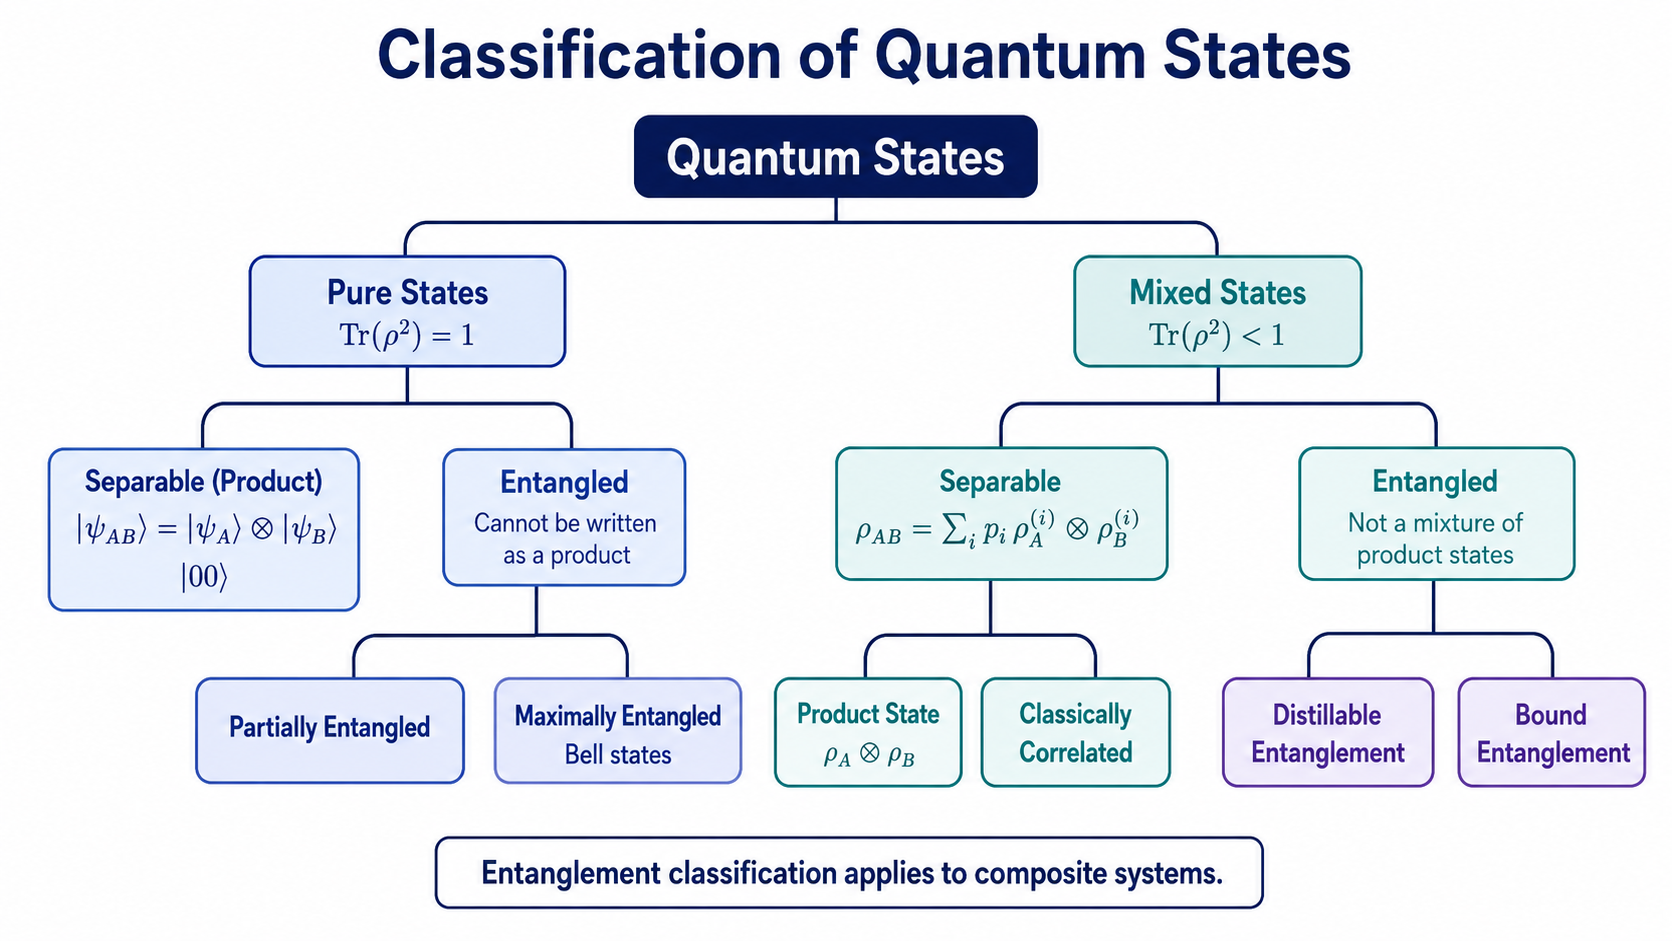

In [1]:
%pip install -e ..
%pip install qiskit
%pip install pylatexenc

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels
Obtaining file:///home/f73aeabd-6de4-471d-92a9-1ba552ae6153/Comput_Quant_Dynam_Study_Package
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for cqd (pyproject.toml) ... done
  Created wheel for cqd: filename=cqd-1.0.0-0.editable-py3-none-any.whl size=2176 sha256=f7532226c47afcd518c699d3ea969fda52854410aa025b65d196d9e40d0bcd15
  Stored in directory: /tmp/pip-ephem-wheel-cache-17wgmuxx/wheels/b0/93/6a/0cc2bd8f76c5148e9cb1241c5fb8169ec308285c23117656ef
Successfully built cqd
  Attempting uninstall: cqd
    Found existing installation: cqd 1.0.0
    Uninstalling cqd-1.0.0:
      Successfully uninstalled cqd-1.0.0
Note: you may need to restart the kernel to use updated packages.
Defaulting to user

In [2]:
import cqd
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import (
    Statevector,
    DensityMatrix,
    partial_trace,
    purity,
)

In [3]:
# Single-qubit computational basis states
ket_0 = np.array([[1], [0]], dtype=complex)
ket_1 = np.array([[0], [1]], dtype=complex)

# Two-qubit computational basis states
ket_00 = np.kron(ket_0, ket_0)
ket_01 = np.kron(ket_0, ket_1)
ket_10 = np.kron(ket_1, ket_0)
ket_11 = np.kron(ket_1, ket_1)

# Density matrices / projectors
rho_00 = ket_00 @ ket_00.conj().T
rho_01 = ket_01 @ ket_01.conj().T
rho_10 = ket_10 @ ket_10.conj().T
rho_11 = ket_11 @ ket_11.conj().T

## 3.1 Mixed States

vector fully describes the state of the system.

$$|\psi\rangle \in \mathcal{H}$$


## Bipartite System

Consider a bipartite system consisting of subsystems $A$ and $B$.

$$
\mathcal{H} = \mathcal{H}_A \otimes \mathcal{H}_B
\
$$

with basis states

$$
|i\rangle \otimes |j\rangle = |i\rangle |j\rangle = |ij\rangle
$$

These are product state basis vectors.


## Measuring Subsystem A
Suppose we measure an observable $\hat{M}_A$ on subsystem $A$, but do not measure subsystem $B$.

Then we measure, ${M}_A \otimes \mathbb{1}_B$

A general pure state of the total system is

$$\psi_{AB}\rangle = \sum_{i,j} c_{ij}|i\rangle |j\rangle
$$


## Expectation Value

$$\langle \psi_{AB}|
\hat{M}_A \otimes \mathbb{1}_B
|\psi_{AB}\rangle$$

Substitute the state:

$$\psi_{AB}\rangle = \sum_{i,j} c_{ij}|i\rangle |j\rangle$$

Then

$$\begin{aligned}
\langle \psi_{AB}|
\hat{M}_A \otimes \mathbb{1}_B
|\psi_{AB}\rangle
&=
\sum_{i,j}
\sum_{i',j'}
c_{ij}^{*}
\langle i|\langle j|
\hat{M}_A \otimes \mathbb{1}_B
|i'\rangle |j'\rangle
c_{i'j'} \\[4pt]
&=
\sum_{i,i'} \sum_j
c_{ij}^{*} c_{i'j}
\langle i|\hat{M}_A|i'\rangle
\end{aligned}
$$
because

$$\langle j|\mathbb{1}_B|j'\rangle = \delta_{jj'}$$


## Reduced Density Matrix

We define the reduced density matrix of subsystem \(A\) as

$$\rho_A =
\operatorname{Tr}_B
\left(
|\psi_{AB}\rangle \langle \psi_{AB}|
\right)$$

Thus,

$$\rho_A =
\sum_{i,i',j}
c_{ij}c_{i'j}^{*}
|i\rangle \langle i'|
$$
This is called the reduced state of subsystem \(A\).
or equivalently,
$$
\rho_A = \operatorname{Tr}_B \left( |\psi_{AB}\rangle \langle \psi_{AB}| \right)
$$
Thus,

$$\rho_A=
\sum_{i,i',j}
c_{ij}c_{i'j}^{*}
|i\rangle \langle i'|$$

This is called the reduced state of subsystem \(A\).

## Trace Formula

The expectation value can now be written as

$$\langle \psi_{AB}|
\hat{M}_A \otimes \mathbb{1}_B
|\psi_{AB}\rangle=
\operatorname{tr}(\rho_A \hat{M}_A)
$$

So even if the full system \(AB\) is in a pure state, subsystem \(A\) may need to be described by a density matrix.


## Trace 

For an operator $X$,

$$\operatorname{tr}(X)=
\sum_k \langle k|X|k\rangle$$

or in matrix form,

$$\operatorname{tr}(X)=
\sum_i X_{ii}$$

## Key Idea

When subsystem $B$ is ignored or not measured, we trace it out:

$$\rho_A = \operatorname{Tr}_B(\rho_{AB})
$$

The reduced density matrix $\rho_A$ contains all the information needed to predict measurement outcomes on subsystem $A$.

In [4]:
dA = 3
dB = 4

rng = np.random.default_rng(8)

# Random complex coefficients 
C = rng.normal(size=(dA, dB)) + 1j * rng.normal(size=(dA, dB))
C = C / np.linalg.norm(C)

# Random Hermitian observable M_A
M_A = rng.normal(size=(dA, dA)) + 1j * rng.normal(size=(dA, dA))
M_A = (M_A + M_A.conj().T) / 2

# Full state vector |psi_AB>
psi_AB = C.reshape(dA * dB)

# Full operator M_A ⊗ I_B
operator_full = np.kron(M_A, np.eye(dB))

# Full expectation value
expectation_full = psi_AB.conj() @ operator_full @ psi_AB

# Reduced density matrix rho_A = C C^\dagger
rho_A = C @ C.conj().T

# Trace expression
expectation_reduced = np.trace(rho_A @ M_A)

print("expectation value=", expectation_full)
print("reduced state=", expectation_reduced)
print("difference=", abs(expectation_full - expectation_reduced))

expectation value= (-0.481473982464628-1.3877787807814457e-17j)
reduced state= (-0.481473982464628+7.806255641895632e-18j)
difference= 2.168404344971009e-17


# Properties of $\rho_A$

The reduced density matrix of subsystem \(A\) is

$$
\rho_A = \operatorname{Tr}_B(\rho_{AB})
$$

It has three important properties.


In [5]:
rho = 0.3 * np.outer(ket_0, ket_0.conj()) + 0.7 * np.outer(ket_1, ket_1.conj())
print("rho =\n", rho)

rho =
 [[0.3+0.j 0. +0.j]
 [0. +0.j 0.7+0.j]]


## 1. Hermitian

$\rho_A^\dagger = \rho_A$ =$(\rho_A^\dagger)_{i'i}=
\sum_j c_{i'j}c_{ij}^{*}
=(\rho_A)_{i'i}$

So $\rho_A$ is Hermitian.

This means its eigenvalues are real.

In [6]:
hermitian = np.allclose(rho.conj().T, rho)
print("Hermitian =", hermitian)

Hermitian = True


## 2. Normalized

A density matrix must have trace equal to one:

${tr}(\rho_A)=\sum_i (\rho_A)_{ii}=\sum_{i,j} c_{ij}c_{ij}^{*}=\sum_{i,j}|c_{ij}|^2=
\langle \psi_{AB}|\psi_{AB}\rangle
=1$

So $\rho_A$ is normalized.

In [7]:
trace_rho = np.trace(rho_00)
print("trace(rho) =", trace_rho)

trace(rho) = (1+0j)


In [8]:
normalized = np.allclose(np.trace(rho), 1)
print(normalized)

True


## 3. Positive semidefinite

$\forall |\phi\rangle \in \mathcal{H}_A$, $\langle \phi|\rho_A|\phi\rangle \geq 0$

The probability (means never negative) of finding subsystem A in state $\phi\rangle$:

$0 \leq
\langle \psi_{AB}|
\left(
|\phi\rangle\langle\phi| \otimes \mathbb{1}_B
\right)
|\psi_{AB}\rangle$

$$=\sum_{i,j}
\sum_{i',j'}
c_{ij}^{*}
\langle i|\langle j|
\left(
|\phi\rangle\langle\phi| \otimes \mathbb{1}_B
\right)
|i'\rangle |j'\rangle
c_{i'j'}$$ $$=\sum_j
\sum_{i,i'}
c_{ij}^{*}c_{i'j}
\langle i|\phi\rangle
\langle\phi|i'\rangle=
\langle \phi|\rho_A|\phi\rangle
$$

It turns out that any operator $\rho$ with these 3 properties can be viewed as the reduced state of a system embedded into a larger system.



Density operator of a system in pure state $|\psi\rangle$ has to be defined as $\rho = |\psi\rangle\langle\psi|$ to be consistent with

$$\langle M\rangle=\operatorname{tr}(M\rho)=
\operatorname{tr}(M|\psi\rangle\langle\psi|)=
\langle\psi|M|\psi\rangle
$$ is a valid density operator.

It fulfills all properties, so it is a mixed state.

---
Calculating $\rho_A$ from $\rho_{AB}$ is called taking the partial trace.

In general,

$$
\rho_A
=
\sum_{i,j}
|i\rangle
\langle i,j|
\rho_{AB}
|i,j\rangle
\langle i|
$$

$$
=
\sum_j
\langle j|_B
\rho_{AB}
|j\rangle_B
$$

$$
=
\operatorname{Tr}_B (\rho_{AB})
$$


In [9]:
eigenvalues = np.linalg.eigvalsh(rho_00)
positive_semidefinite = np.all(eigenvalues >= -1e-12)

print("Positive semidefinite rho >= 0:", positive_semidefinite)
print("eigenvalues =", eigenvalues)
print("Purity tr(rho^2) =", cqd.states.purity(rho_00))

Positive semidefinite rho >= 0: True
eigenvalues = [0. 0. 0. 1.]
Purity tr(rho^2) = (1+0j)


## 1) Pure State 

Consider the bipartite product state:

$$
|\psi_{AB}\rangle = |0_A 0_B\rangle
$$

To find the reduced density matrix $\rho_A$, we compute the partial trace over subsystem $B$. Taking the trace in the computational basis $\{|0_B\rangle, |1_B\rangle\}$:

$$
\begin{aligned}
\rho_A &= \operatorname{Tr}_B \left(|\psi_{AB}\rangle\langle\psi_{AB}|\right) \\
&= \langle 0_B|\psi_{AB}\rangle\langle\psi_{AB}|0_B\rangle + \langle 1_B|\psi_{AB}\rangle\langle\psi_{AB}|1_B\rangle \\
&= |0_A\rangle\langle 0_A| + 0 \\
&= |0_A\rangle\langle 0_A| \quad \Rightarrow \quad \text{pure state!}
\end{aligned}
$$

In matrix form relative to the basis $\{|0_A\rangle, |1_A\rangle\}$:

$$
\rho_A = 
\begin{pmatrix}
1 & 0 \\
0 & 0
\end{pmatrix}
$$


###  Summery  for Tensor Product 

We can also find the reduced density matrix $\rho_A$ directly using tensor product properties:

$$
\rho_A = \operatorname{Tr}_B(\rho_{AB}) = \operatorname{Tr}_B\left(|00\rangle_{AB}\langle00|\right)
$$

Because the joint state is a product state:

$$
|00\rangle_{AB} = |0\rangle_A \otimes |0\rangle_B
$$

The full density matrix factors as:

$$
|00\rangle\langle00| = \left(|0\rangle_A\langle0|_A\right) \otimes \left(|0\rangle_B\langle0|_B\right)
$$

Using the identity for partial traces of tensor products:

$$
\operatorname{Tr}_B(X_A \otimes Y_B) = X_A \operatorname{Tr}(Y_B)
$$

We apply it directly:

$$
\begin{aligned}
\rho_A &= \operatorname{Tr}_B \left[ \left(|0\rangle_A\langle0|_A\right) \otimes \left(|0\rangle_B\langle0|_B\right) \right] \\[6pt]
&= |0\rangle_A\langle0|_A \, \operatorname{Tr}\left(|0\rangle_B\langle0|_B\right)
\end{aligned}
$$

Since the trace of a normalized state is unity ($\operatorname{Tr}\left(|0\rangle_B\langle0|_B\right) = 1$), we obtain:

$$
\rho_A = |0\rangle_A\langle0|_A
$$

In [10]:
rho_0 = np.kron(ket_0, ket_0.conj().T)
print("rho =\n", rho_0)
print()
print("Purity tr(rho^2) =", cqd.states.purity(rho_0))

rho =
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]

Purity tr(rho^2) = (1+0j)


In [11]:
rho_00 =  np.outer(ket_00, ket_00.conj().T) 
print("rho =\n", rho_00)
print()
print("Purity tr(rho^2) =", cqd.states.purity(rho_00))

rho =
 [[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]

Purity tr(rho^2) = (1+0j)


## 2) Entangled State 

Maximally entangled state(Bell State)

$$
|\psi_{AB}\rangle = \frac{1}{\sqrt{2}} \left( |0_A 0_B\rangle + |1_A 1_B\rangle \right)
$$

Tracing out subsystem $B$:

$$
\begin{aligned}
\rho_A &= \langle 0_B|\psi_{AB}\rangle\langle\psi_{AB}|0_B\rangle + \langle 1_B|\psi_{AB}\rangle\langle\psi_{AB}|1_B\rangle \\
&= \frac{1}{2} \left( |0_A\rangle\langle 0_A| + |1_A\rangle\langle 1_A| \right) \neq |\psi_A\rangle\langle\psi_A|
\end{aligned}
$$

In the computational basis $\{|0\rangle, |1\rangle\}$:

$$
\rho_A = 
\begin{pmatrix}
1/2 & 0 \\
0 & 1/2
\end{pmatrix}
= \frac{1}{2} \mathbb{1}
$$

This represents a **maximally mixed state**.

In [12]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

qc_00 = QuantumCircuit(2)

ket_00 = Statevector.from_instruction(qc_00)
print(ket_00.draw("text"))

[1.+0.j,0.+0.j,0.+0.j,0.+0.j]


Phi_plus Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

Ket notation: [0.70710678+0.j,0.        +0.j,0.        +0.j,0.70710678+0.j]



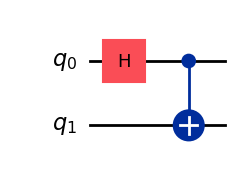

In [13]:
qc = QuantumCircuit(2) # Create a two-qubit quantum circuit initialized in |00>
qc.h(0) # Apply a Hadamard gate to the first qubit, q0
# Apply a controlled-X (CNOT) gate:
# q0 is the control qubit and q1 is the target qubit
qc.cx(0, 1)
# Obtain the statevector produced by the circuit
Phi_plus = Statevector.from_instruction(qc)
print("Phi_plus", Phi_plus) # Display the statevector
print()
print("Ket notation:", Phi_plus.draw("text")) # Display the state in ket notation
print()
display(qc.draw("mpl")) # calculate the purity for Maximula entagled state 

In [14]:
# calculate the purity for this for maximally entangled state of Phi_plus
rho_Phi_plus = DensityMatrix(Phi_plus)
print("Purity tr(rho_Phi_plus^2) =", cqd.states.purity(rho_Phi_plus))

Purity tr(rho_Phi_plus^2) = (0.9999999999999996+0j)


Phi_minus Statevector([ 0.70710678+0.j,  0.        +0.j,  0.        +0.j,
             -0.70710678+0.j],
            dims=(2, 2))

Ket notation: [ 0.70710678+0.j, 0.        +0.j, 0.        +0.j,-0.70710678+0.j]



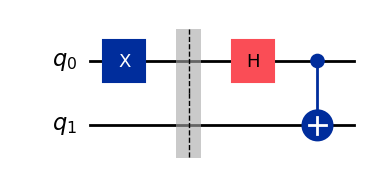

In [15]:
qc = QuantumCircuit(2) # Create a two-qubit quantum circuit initialized in |00>
qc.x(0) # apply X gate for bit flip q0: |0> → |1>  which changes (X*I)|00> → |10>
qc.barrier()
qc.h(0) # Apply a Hadamard gate to the first qubit, q0
# Apply a controlled-X (CNOT) gate:
# q0 is the control qubit and q1 is the target qubit
qc.cx(0, 1)
# Obtain the statevector produced by the circuit
Phi_minus = Statevector.from_instruction(qc)
print("Phi_minus", Phi_minus) # Display the statevector
print()
print("Ket notation:", Phi_minus.draw("text")) # Display the state in ket notation
print()
display(qc.draw("mpl")) # calculate the purity for Maximula entagled state 

In [16]:
# calculate the purity for this for maximally entangled state of Phi_minus
rho_Phi_minus = DensityMatrix(Phi_minus)
print("Purity tr(rho_Phi_minus^2) =", cqd.states.purity(rho_Phi_minus))

Purity tr(rho_Phi_minus^2) = (0.9999999999999996+0j)


Psi_plus Statevector([0.        +0.j, 0.70710678+0.j, 0.70710678+0.j,
             0.        +0.j],
            dims=(2, 2))

Ket notation: [0.        +0.j,0.70710678+0.j,0.70710678+0.j,0.        +0.j]



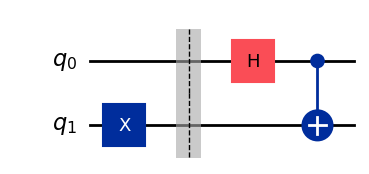

In [17]:
qc = QuantumCircuit(2) # Create a two-qubit quantum circuit initialized in |00>
qc.x(1) # apply X gate for bit flip  on the first qubits(q0): |0> → |1>  which changes (X*I)|00> → |10>
qc.barrier()
qc.h(0) # Apply a Hadamard gate to the first qubit, q0
# Apply a controlled-X (CNOT) gate:
# q0 is the control qubit and q1 is the target qubit
qc.cx(0, 1)
# Obtain the statevector produced by the circuit
Psi_plus = Statevector.from_instruction(qc)
print("Psi_plus", Psi_plus) # Display the statevector
print()
print("Ket notation:", Psi_plus.draw("text")) # Display the state in ket notation
print()
display(qc.draw("mpl")) # calculate the purity for Maximula entagled state  

In [18]:
# calculate the purity for this for maximally entangled state of Psi_plus
rho_Psi_plus = DensityMatrix(Psi_plus)
print("Purity tr(rho_Psi_plus^2) =", cqd.states.purity(rho_Psi_plus))

Purity tr(rho_Psi_plus^2) = (0.9999999999999996+0j)


psi_minus Statevector([ 0.        +0.j, -0.70710678+0.j,  0.70710678+0.j,
              0.        +0.j],
            dims=(2, 2))

phi_minus [ 0.        +0.j,-0.70710678+0.j, 0.70710678+0.j, 0.        +0.j]



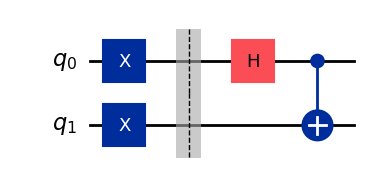

In [19]:
qc = QuantumCircuit(2) # Create a two-qubit quantum circuit initialized in |00>
# Apply X to both qubits which changes (X*X)|00> → |11>
qc.x(0)
qc.x(1)
qc.barrier()
qc.h(0) # Apply a Hadamard gate to the first qubit, q0
# Apply a controlled-X (CNOT) gate:
# q0 is the control qubit and q1 is the target qubit
qc.cx(0, 1)
# Obtain the statevector produced by the circuit
Psi_minus = Statevector.from_instruction(qc)
print("psi_minus", Psi_minus) # Display the statevector
print()
print("phi_minus", Psi_minus.draw("text")) # Display the state in ket notation
print()
display(qc.draw("mpl")) # calculate the purity for Maximula entagled state 

In [20]:
# calculate the purity for this for maximally entangled state of Psi_minus
rho_Psi_minus = DensityMatrix(Psi_minus)
print("Purity tr(rho_Psi_minus^2) =", cqd.states.purity(rho_Psi_minus))

Purity tr(rho_Psi_minus^2) = (0.9999999999999996+0j)


## Purity of a Quantum State

on the above fours example all state is pure state the have one purity in the trace 

The quantity $\operatorname{Tr}(\rho^2)$ is defined as the **purity** of the density operator $\rho$.

1. **For Pure States:** $\rho = |\psi\rangle\langle\psi|$
   $$
   \rho^2 = (|\psi\rangle\langle\psi|)(|\psi\rangle\langle\psi|) = |\psi\rangle\langle\psi| = \rho
   $$
   $$
   \Rightarrow \operatorname{Tr}(\rho^2) = \operatorname{Tr}(\rho) = 1
   $$

In [21]:
# Store all four Bell states
bell_states = {
    "Phi_plus": Phi_plus,
    "Phi_minus": Phi_minus,
    "Psi_plus": Psi_plus,
    "Psi_minus": Psi_minus,
}

# Convention:
# subsystem A = q0
# subsystem B = q1

for state_name, statevector in bell_states.items():

    # Full two-qubit density matrix:
    # rho_AB = |psi_AB><psi_AB|
    rho_AB = DensityMatrix(statevector)

    # Trace out subsystem B = q1, leaving rho_A
    rho_A = partial_trace(rho_AB, [1])

    # Trace out subsystem A = q0, leaving rho_B
    rho_B = partial_trace(rho_AB, [0])

    # Calculate purities
    purity_AB = purity(rho_AB)
    purity_A = purity(rho_A)
    purity_B = purity(rho_B)

    print("=" * 50)
    print("Bell state:", state_name)

    print("\nFull density matrix rho_AB:")
    print(np.round(rho_AB.data, 3))

    print("\nReduced density matrix rho_A:")
    print(np.round(rho_A.data, 3))

    print("\nReduced density matrix rho_B:")
    print(np.round(rho_B.data, 3))

    print("\nFull-state purity =", purity_AB)
    print("Reduced-state purity of A =", purity_A)
    print("Reduced-state purity of B =", purity_B)

print("=" * 50)

Bell state: Phi_plus

Full density matrix rho_AB:
[[0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0.5+0.j 0. +0.j 0. +0.j 0.5+0.j]]

Reduced density matrix rho_A:
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

Reduced density matrix rho_B:
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

Full-state purity = (0.9999999999999996+0j)
Reduced-state purity of A = (0.4999999999999998+0j)
Reduced-state purity of B = (0.4999999999999998+0j)
Bell state: Phi_minus

Full density matrix rho_AB:
[[ 0.5+0.j  0. +0.j  0. +0.j -0.5-0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. -0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. -0.j]
 [-0.5+0.j  0. +0.j  0. +0.j  0.5+0.j]]

Reduced density matrix rho_A:
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

Reduced density matrix rho_B:
[[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]

Full-state purity = (0.9999999999999996+0j)
Reduced-state purity of A = (0.4999999999999998+0j)
Reduced-state purity of B = (0.4999999999999998+0j)
Bell state: Psi_plus

F

2. **For Mixed States:**
   $$
   \operatorname{Tr}(\rho^2) < 1
   $$
   In this case, the state cannot be written in the form $|\psi\rangle\langle\psi|$.

3. **Maximally Mixed State in $d$ Dimensions:**
   For a state given by $\rho = \frac{\mathbb{1}}{d}$:
   $$
   \operatorname{Tr}\left[\left(\frac{\mathbb{1}}{d}\right)^2\right] = \sum_{i=1}^{d} \frac{1}{d^2} = \frac{d}{d^2} = \frac{1}{d}
   $$
   Here, the purity reaches its absolute minimum value of $\frac{1}{d}$.

In [22]:
for state_name, statevector in bell_states.items():

    # Complete two-qubit density matrix
    rho_AB = DensityMatrix(statevector)

    # Trace out subsystem B = q1, leaving subsystem A = q0
    rho_A = partial_trace(rho_AB, [1])

    # Calculate the purity of the reduced state
    purity_A = cqd.states.purity(rho_A.data)

    print(
        f"Reduced-state purity  ({state_name}) =",
        np.real_if_close(purity_A)
    )

Reduced-state purity  (Phi_plus) = 0.4999999999999998
Reduced-state purity  (Phi_minus) = 0.4999999999999998
Reduced-state purity  (Psi_plus) = 0.4999999999999998
Reduced-state purity  (Psi_minus) = 0.4999999999999998


## Summery Purity of the Bell State

### 1. Full-Two-qubit state

For the complete Bell-state density matrix,

$$
\rho_{AB} = |\psi_{AB}\rangle\langle\psi_{AB}|
$$

the purity is

$$
\operatorname{Tr}\left(\rho_{AB}^{2}\right) = 1
$$

Therefore, the complete Bell state is a **pure maximally entangled state**.


### 2. Reduced single-qubit state

After tracing out subsystem $B$,

$$
\rho_A = \operatorname{Tr}_B(\rho_{AB}) = \frac{\mathbb{I}_2}{2} = \begin{pmatrix} \frac{1}{2} & 0 \\ 0 & \frac{1}{2} \end{pmatrix}
$$

The purity of the reduced state is

$$
\operatorname{Tr}\left(\rho_A^{2}\right) = \frac{1}{2}
$$

Therefore, each individual qubit is in a **maximally mixed state**.


### Summary

$$
\boxed{\text{Full-state purity} = 1}
$$

$$
\boxed{\text{Reduced-state purity} = 0.5}
$$

# 8.2 Entanglement

Consider a composite system \(A,B\).

Here, consider only bipartite entanglement of pure states.

$$
|\psi_{AB}\rangle
=
|\psi_A\rangle \otimes |\psi_B\rangle
\quad
\text{is called separable.}
$$

If $|\psi_{AB}\rangle $  is not separable, it is called entangled.


For mixed states,

$
\rho
=
\sum_i
p_i
\rho_A^{(i)}
\otimes
\rho_B^{(i)}
$,  is called separable.

---

For separable pure states, the reduced state $\rho_A$ is pure:

$$
\rho_A
=
\sum_{i_B}
\langle i_B|\psi_{AB}\rangle
\langle\psi_{AB}|i_B\rangle
$$

$$
=
\sum_{i_B}
\langle i_B|
\left(
|\psi_A\rangle|\psi_B\rangle
\langle\psi_A|\langle\psi_B|
\right)
|i_B\rangle
$$

$$
=
|\psi_A\rangle\langle\psi_A|
\sum_{i_B}
\langle i_B|\psi_B\rangle
\langle\psi_B|i_B\rangle
$$

$$
=
|\psi_A\rangle\langle\psi_A|
\sum_{i_B}
|\langle i_B|\psi_B\rangle|^2
=
|\psi_A\rangle\langle\psi_A|
$$


$$
|\psi_{AB}\rangle
\text{ is entangled}
\Longleftrightarrow
\operatorname{tr}(\rho_A^2)<1
$$

This is not true if $\rho_{AB}$ is mixed.

For example,

$$
|\psi_{AB}\rangle
=
\frac{1}{\sqrt{2}}
\left(
|00\rangle + |11\rangle
\right)
$$

is entangled, and

$$
\operatorname{tr}(\rho_A^2)
=
\operatorname{tr}
\left[
\begin{pmatrix}
1/2 & 0 \\
0 & 1/2
\end{pmatrix}^2
\right]
=
\operatorname{tr}
\left[
\begin{pmatrix}
1/4 & 0 \\
0 & 1/4
\end{pmatrix}
\right]
=
\frac{1}{2}<1
$$

---

Eigenvalues of $\rho_A$ are called the entanglement spectrum:

$$
\lambda_1 \geq \lambda_2 \geq \cdots \geq \lambda_k
$$

Only non-zero $\lambda_i$ 's are written in decreasing order.

Number of non-zero elements $k$ is called Schmidt rank / entanglement dimension.

$$
\sqrt{\lambda_i}
$$

are Schmidt coefficients.

For separable states,

$$
k=1
$$

Therefore,

$$
|\psi_{AB}\rangle
\text{ entangled}
\Longleftrightarrow
\text{Schmidt rank}>1
$$

In [23]:
psi_AB = np.kron(ket_0, ket_0)
# density matrix rho_AB = |psi_AB><psi_AB|
rho_AB = cqd.states.density_matrix(psi_AB)

# Reduced density matrix rho_A = Tr_B(rho_AB)
rho_A = cqd.states.partial_trace(rho_AB, dA=2, dB=2)

# Purity Tr(rho_A^2)
purity_A = cqd.states.purity(rho_A)

print("psi_AB =", psi_AB)
print()
print("rho_AB =", rho_AB)
print()
print("rho_A =", rho_A)
print()
print("rho_A squared =", rho_A @ rho_A)
print()
print("Tr(rho_A^2) =", purity_A)

psi_AB = [[1.+0.j]
 [0.+0.j]
 [0.+0.j]
 [0.+0.j]]

rho_AB = [[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]

rho_A = [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]

rho_A squared = [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]

Tr(rho_A^2) = (1+0j)


# Entropies

## Von Neumann entanglement entropy ($S_E(...)$)

$$
S_E(\rho_A)
=
-\operatorname{tr}(\rho_A \log \rho_A)
=
-\sum_{i=1}^{k}
\lambda_i \log \lambda_i
$$

## \(n\)-th Rényi entropy ($S_n(...)$)

$$
S_n(\rho_A)
=
\frac{1}{1-n}
\log \operatorname{tr}(\rho_A^n)
=
\frac{1}{1-n}
\log
\sum_i \lambda_i^n
$$

---

$$
\lim_{n\to 1} S_n(\rho_A) = S_E(\rho_A)
$$

$$
S_2(\rho_A)
=
-\log \operatorname{tr}(\rho_A^2)
$$

$$
\operatorname{tr}(\rho_A^2)
\quad
\text{is the purity}
$$

---

$$
S_E = S_n = 0
\quad
\text{for separable states}
$$

$$
S_E > 0,
\qquad
S_n > 0
\quad
\text{for entangled states}
$$

---

$$
S \text{ maximal if }
\rho_A = \frac{\mathbb{1}}{d_A}
$$

For example,

$$
S_2(\rho_A)=\log d_A
$$

For spins,

$$
d_A = 2^{N_A}
$$

so

$$
S_2(\rho_A)
=
N_A \log 2
$$

Usually log base \(2\) is used.

This is called **maximally entangled**.

# 8.3 Schmidt Decomposition

Any bipartite pure state can be written as

$|\psi_{AB}\rangle=
\sum_{i=1}^{k}
\alpha_i
|i_A\rangle
\otimes
|i_B\rangle$,   $\alpha_i \in \mathbb{R}^{+}$

Where as $|i_A\rangle,
|i_B\rangle, k \leq
\min
\left(
\dim \mathcal{H}_A,
\dim \mathcal{H}_B
\right)
$
are orthonormal states in $\mathcal{H}_A,\mathcal{H}_B$respectively. We can identify $\alpha_i =\sqrt{\lambda_i}$

---

## Proof

From$
|\psi_{AB}\rangle
$
we can calculate$
\rho_A
$ and diagonalize it:

$$
\rho_A
=
\sum_i
\lambda_i
|i\rangle\langle i|
$$

with orthonormal states $|i\rangle \in \mathcal{H}_A$

Fill $\{|i\rangle\}$ up to a basis of $\mathcal{H}_A$ and terms with $\lambda_i = 0$
Choose an ONB of \(\mathcal{H}_B\): \(\{|q_j\rangle\}\)

$$
\Rightarrow
\{|i\rangle_A \otimes |q_j\rangle_B\}
\text{ is basis of } \mathcal{H}
$$

$$
\Rightarrow
|\psi_{AB}\rangle
=
\sum_{i,j}
c_{ij}
|i\rangle_A
|q_j\rangle_B
=
\sum_i
|i\rangle_A
\sum_j
c_{ij}|q_j\rangle_B
$$

$$
=
\sum_i
|i\rangle_A
|\chi_i\rangle_B
$$

Rewrite \(\rho_A\) with this definition and compare to the diagonal form:

$$
\rho_A
=
\operatorname{Tr}_B
|\psi_{AB}\rangle\langle\psi_{AB}|
=
\operatorname{Tr}_B
\left(
\sum_{i,i'}
|i\rangle\langle i'|
\otimes
|b_i\rangle\langle b_{i'}|
\right)
$$

$$
=
\sum_{i,i'}
|i\rangle\langle i'|
\left(
\sum_j
\langle j|b_i\rangle
\langle b_{i'}|j\rangle
\right)
$$

$$
=
\sum_{i,i'}
|i\rangle\langle i'|
\langle b_{i'}|b_i\rangle
$$

$$
=
\sum_i
\lambda_i
|i\rangle\langle i|
$$

Compare coefficients of (1) and (2), which have to be equal since \(\{|i\rangle\}\) are orthonormal:

$$
\Rightarrow
\langle b_{i'}|b_i\rangle
=
\delta_{ii'}\lambda_i
$$

$$
\Rightarrow
|i\rangle_B
:=
\frac{|b_i\rangle}{\sqrt{\lambda_i}}
\quad
\text{are orthonormal in } \mathcal{H}_B
$$

$$
\Rightarrow
|\psi_{AB}\rangle
=
\sum_i
\sqrt{\lambda_i}
|i\rangle_A
|i\rangle_B
$$

$$
\Rightarrow
\text{for pure states, }
\rho_A=\operatorname{Tr}_B(\rho)
\text{ and }
\rho_B=\operatorname{Tr}_A(\rho)
\text{ have the same eigenvalues } \lambda_i
$$

In [24]:
psi_AB = np.kron(ket_0, ket_0)
rho_AB = cqd.states.density_matrix(psi_AB)
rho_A = cqd.states.partial_trace(rho_AB, dA=2, dB=2,)
purity_A = cqd.states.purity(rho_A)

## Singular Value Decomposition (SVD) & Schmidt Decomposition

### 1. Goal: Finding the Schmidt Form
An arbitrary bipartite state $|\Psi_{AB}\rangle$ in a product basis $\{|a_m\rangle \otimes |b_n\rangle\}$ can be written as:
$$|\Psi_{AB}\rangle = \sum_{m=1}^{d_A} \sum_{n=1}^{d_B} C_{mn} |a_m\rangle |b_n\rangle \xrightarrow{\text{Goal}} \sum_{i=1}^{k} \alpha_i |i\rangle_A |i\rangle_B$$
Our target is to explicitly find the positive coefficients $\alpha_i$ and the new local bases $\{|i\rangle_A\}$ and $\{|i\rangle_B\}$.

### Example: Constructing a Bipartite State

Consider two qubits with the computational basis

$$
\{|00\rangle,|01\rangle,|10\rangle,|11\rangle\}.
$$

We define the normalized bipartite state

$$
|\Psi_{AB}\rangle
=
\frac{\sqrt{3}}{2\sqrt{2}}|00\rangle
+
\frac{1}{2\sqrt{2}}|01\rangle
+
\frac{\sqrt{3}}{2\sqrt{2}}|10\rangle
-
\frac{1}{2\sqrt{2}}|11\rangle.
$$

The state can be written generally as

$$
|\Psi_{AB}\rangle
=
\sum_{m=0}^{1}
\sum_{n=0}^{1}
C_{mn}|m\rangle_A|n\rangle_B.
$$

The coefficients $C_{mn}$ form the coefficient matrix

$$
C
=
\begin{pmatrix}
C_{00} & C_{01}\\
C_{10} & C_{11}
\end{pmatrix}.
$$

Our goal is to rewrite the state in Schmidt form:

$$
|\Psi_{AB}\rangle
=
\sum_{i=1}^{k}
\alpha_i
|u_i\rangle_A
|v_i\rangle_B.
$$

In [25]:
# Construct the bipartite state
psi_AB = (
    np.sqrt(3) / (2 * np.sqrt(2)) * ket_00
    + 1 / (2 * np.sqrt(2)) * ket_01
    + np.sqrt(3) / (2 * np.sqrt(2)) * ket_10
    - 1 / (2 * np.sqrt(2)) * ket_11
)

print(psi_AB)
print("\nNorm=", np.linalg.norm(psi_AB))

Statevector([ 0.61237244+0.j,  0.35355339+0.j,  0.61237244+0.j,
             -0.35355339+0.j],
            dims=(2, 2))

Norm= 0.9999999999999999


### 2. SVD of the Coefficient Matrix
We treat the coefficients $C_{mn}$ as a rectangular $d_A \times d_B$ complex matrix $C$. Any such matrix can be broken down using **Singular Value Decomposition (SVD)**:

$$C = U D V^\dagger$$

* **$U$:** Unitary matrix of size $d_A \times d_A$
* **$V^\dagger$:** Unitary matrix of size $d_B \times d_B$
* **$D$:** Diagonal $d_A \times d_B$ rectangular matrix containing **singular values** $\alpha_i \ge 0$ along the main diagonal:
  $$D = \begin{pmatrix} \alpha_1 & & & \\ & \ddots & & \\ & & \alpha_k & \\ & & & 0 \end{pmatrix}$$

#### In Components:
$$C_{mn} = \sum_{i} U_{mi} \alpha_i V_{ni}^* \quad \text{(summing only over non-zero } \alpha_i\text{)}$$

### Example: Singular Value Decomposition of the Coefficient Matrix

For two qubits, the dimensions are

$$
d_A=d_B=2.
$$

The flat state vector is reshaped into the coefficient matrix

$$
C
=
\begin{pmatrix}
C_{00} & C_{01}\\
C_{10} & C_{11}
\end{pmatrix}.
$$

For the chosen state,

$$
C
=
\begin{pmatrix}
\dfrac{\sqrt{3}}{2\sqrt{2}}
&
\dfrac{1}{2\sqrt{2}}
\\[8pt]
\dfrac{\sqrt{3}}{2\sqrt{2}}
&
-\dfrac{1}{2\sqrt{2}}
\end{pmatrix}.
$$

We perform the singular value decomposition

$$
C=UDV^\dagger.
$$

The diagonal entries of $D$ are the Schmidt coefficients.

In [26]:
# Dimensions of the two subsystems
d_A = 2
d_B = 2

# Convert the Qiskit Statevector into a NumPy array
psi_array = np.asarray(psi_AB.data, dtype=complex)

print("State vector amplitudes:")
print(psi_array)

# Check that the dimensions are correct
if psi_array.size != d_A * d_B:
    raise ValueError(
        f"The state contains {psi_array.size} amplitudes, "
        f"but d_A * d_B = {d_A * d_B}."
    )

# Reshape the state vector into the coefficient matrix
C = psi_array.reshape(d_A, d_B)

print("\nCoefficient matrix C:")
print(C)

# Singular value decomposition: C = U D V†
U, singular_values, Vh = np.linalg.svd(
    C,
    full_matrices=False,
)

# Construct the diagonal singular-value matrix
D = np.diag(singular_values)
print("\nU =", U)
print("\nD =\n", D)
print("\nV dagger =\n", Vh)
print("\nSchmidt coefficients =\n", singular_values)

# Reconstruct the coefficient matrix
C_reconstructed = U @ D @ Vh
print("\nReconstructed coefficient matrix\n", C_reconstructed)
print("\nDoes U @ D @ Vh equal C?", np.allclose(C, C_reconstructed))

State vector amplitudes:
[ 0.61237244+0.j  0.35355339+0.j  0.61237244+0.j -0.35355339+0.j]

Coefficient matrix C:
[[ 0.61237244+0.j  0.35355339+0.j]
 [ 0.61237244+0.j -0.35355339+0.j]]

U = [[-0.70710678+0.j -0.70710678+0.j]
 [-0.70710678+0.j  0.70710678+0.j]]

D =
 [[0.8660254 0.       ]
 [0.        0.5      ]]

V dagger =
 [[-1.+0.j -0.+0.j]
 [-0.+0.j -1.+0.j]]

Schmidt coefficients =
 [0.8660254 0.5      ]

Reconstructed coefficient matrix
 [[ 0.61237244+0.j  0.35355339+0.j]
 [ 0.61237244+0.j -0.35355339+0.j]]

Does U @ D @ Vh equal C? True


### 3. Deriving the Schmidt Decomposition
Substituting the component form of $C_{mn}$ back into the state vector yields:

$$
\begin{aligned}
|\Psi_{AB}\rangle &= \sum_{m,n} \left( \sum_{i} U_{mi} \alpha_i V_{ni}^* \right) |a_m\rangle |b_n\rangle \\
&= \sum_{i} \alpha_i \underbrace{\left( \sum_{m} U_{mi} |a_m\rangle \right)}_{|i\rangle_A} \otimes \underbrace{\left( \sum_{n} V_{ni}^* |b_n\rangle \right)}_{|i\rangle_B}
\end{aligned}
$$

> ### Key Conclusions
> * Because $U$ and $V^\dagger$ are unitary, the newly defined local state sets $\{|i\rangle_A\}$ and $\{|i\rangle_B\}$ are guaranteed to be strictly **orthonormal**.
> * This directly recovers the **Schmidt decomposition** of a bipartite state.
> * The matrix **singular values ($\alpha_i$)** are exactly equivalent to the **Schmidt coefficients**.

### Example: Constructing the Schmidt Decomposition

From the SVD,

$$
C_{mn}
=
\sum_i
U_{mi}\alpha_i(V^\dagger)_{in}.
$$

The Schmidt states of subsystem $A$ are obtained from the columns of $U$:

$$
|u_i\rangle_A
=
\sum_m U_{mi}|m\rangle_A.
$$

The Schmidt states of subsystem $B$ are obtained from the rows of
$V^\dagger$:

$$
|v_i\rangle_B
=
\sum_n(V^\dagger)_{in}|n\rangle_B.
$$

Therefore,

$$
|\Psi_{AB}\rangle
=
\sum_i
\alpha_i
|u_i\rangle_A
|v_i\rangle_B.
$$

In [27]:
# Number of nonzero Schmidt coefficients
tolerance = 1e-12
schmidt_rank = np.sum(singular_values > tolerance)

print("Schmidt rank=", schmidt_rank)

for i in range(schmidt_rank):
    alpha_i = singular_values[i]
    ket_u_i = U[:, i]
    ket_v_i = Vh[i, :]

    print(f"\nSchmidt term {i + 1}")
    print("alpha_i =", alpha_i)
    print("|u_i>_A =", ket_u_i)
    print("|v_i>_B =", ket_v_i)

Schmidt rank= 2

Schmidt term 1
alpha_i = 0.8660254037844386
|u_i>_A = [-0.70710678+0.j -0.70710678+0.j]
|v_i>_B = [-1.+0.j -0.+0.j]

Schmidt term 2
alpha_i = 0.49999999999999994
|u_i>_A = [-0.70710678+0.j  0.70710678+0.j]
|v_i>_B = [-0.+0.j -1.+0.j]


In [28]:
# Reconstruct the state from the Schmidt terms

psi_schmidt = np.zeros_like(psi_AB)

for i in range(schmidt_rank):
    alpha_i = singular_values[i]
    ket_u_i = U[:, i]
    ket_v_i = Vh[i, :]

    psi_schmidt += alpha_i * np.kron(
        ket_u_i,
        ket_v_i,
    )

print("initial state:", psi_AB)
print("\nState reconstructed from Schmidt decomposition:", psi_schmidt)
print("\nReconstruction correct:", np.allclose(psi_AB, psi_schmidt))

initial state: Statevector([ 0.61237244+0.j,  0.35355339+0.j,  0.61237244+0.j,
             -0.35355339+0.j],
            dims=(2, 2))

State reconstructed from Schmidt decomposition: [ 0.61237244+0.j  0.35355339+0.j  0.61237244+0.j -0.35355339+0.j]

Reconstruction correct: True


## 8.5 Practical Considerations

### 1. Numerical Calculation of Reduced Density Matrices for Spin Systems

#### Example: Two Spin-1/2 Particles
* **Basis:** $\{|00\rangle, |01\rangle, |10\rangle, |11\rangle\}$
* **Density Matrix Elements:** For a pure global state $|\Psi_{AB}\rangle = \sum_{i_A, i_B} C_{i_A i_B} |i_A i_B\rangle$:
  $$\rho_{i_A i_B, \, j_A j_B} = \langle i_A i_B | \rho | j_A j_B \rangle = C_{i_A i_B} C_{j_A j_B}^*$$

* **Partial Trace over the 1st Spin:** To find the reduced state of the 2nd spin ($\rho^{(B)}$), we trace out subsystem $A$:
  $$\left(\rho^{(B)}\right)_{0,0} = \sum_{i_A} \rho_{i_A 0, \, i_A 0} = \rho_{00,00} + \rho_{10,10}$$
  $$\left(\rho^{(B)}\right)_{0,1} = \sum_{i_A} \rho_{i_A 0, \, i_A 1} = \rho_{00,01} + \rho_{10,11}$$

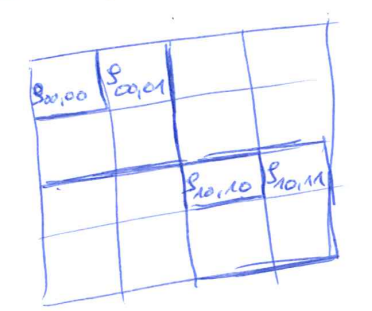

* **Visual Insight:** Finding the partial trace reduces to **adding the diagonal blocks** of the full density matrix.

---

#### General Case: $N$ Spin-1/2 Particles (Tracing out first $N-M$ spins)
To get the reduced state $\rho^{(B)}$ of the final $M$ spins, take the partial trace over the first $N-M$ spins:
$$\rho^{(B)} = \sum_{K=0}^{2^{N-M}-1} \rho_{KK}^{[2^M]}$$

* Where $\rho_{KK}^{[2^M]}$ represents the $K$-th sub-block along the diagonal.
* Each sub-block has dimensions $2^M \times 2^M$.

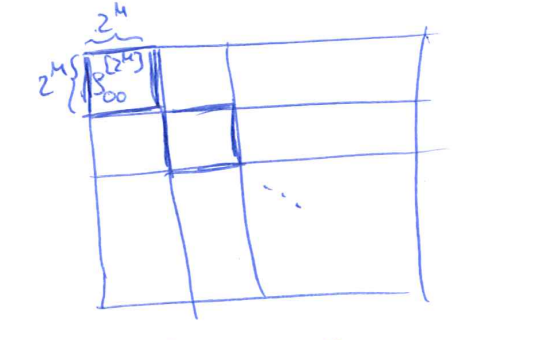


### Example: Reduced Density Matrices of Two Spin-$1/2$ Particles

The density matrix of the complete pure state is

$$
\rho_{AB}
=
|\Psi_{AB}\rangle
\langle\Psi_{AB}|.
$$

The reduced density matrix of subsystem $B$ is obtained by tracing out
subsystem $A$:

$$
\rho_B
=
\operatorname{Tr}_A(\rho_{AB}).
$$

In components,

$$
(\rho_B)_{nn'}
=
\sum_m
(\rho_{AB})_{mn,mn'}.
$$

Using the basis ordering

$$
\{|00\rangle,|01\rangle,|10\rangle,|11\rangle\},
$$

the full density matrix can be divided into four $2\times2$ blocks.
The reduced density matrix $\rho_B$ is obtained by adding the two
diagonal blocks.

In [29]:
# Convert the Qiskit Statevector into a flat NumPy array
psi_array = np.asarray(psi_AB.data, dtype=complex).reshape(-1)

# Full density matrix: rho_AB = |psi_AB><psi_AB|
rho_AB = np.outer(psi_array, psi_array.conj())

print("State vector |psi_AB>:", psi_array)
print("\nFull density matrix rho_AB:\n", rho_AB)

State vector |psi_AB>: [ 0.61237244+0.j  0.35355339+0.j  0.61237244+0.j -0.35355339+0.j]

Full density matrix rho_AB:
 [[ 0.375     +0.j  0.21650635+0.j  0.375     +0.j -0.21650635-0.j]
 [ 0.21650635+0.j  0.125     +0.j  0.21650635+0.j -0.125     -0.j]
 [ 0.375     +0.j  0.21650635+0.j  0.375     +0.j -0.21650635-0.j]
 [-0.21650635+0.j -0.125     +0.j -0.21650635+0.j  0.125     +0.j]]


In [30]:
# For d_A = d_B = 2, divide rho_AB into 2 x 2 blocks

block_00 = rho_AB[0:2, 0:2]
block_11 = rho_AB[2:4, 2:4]

# Trace out subsystem A by adding diagonal blocks
rho_B_blocks = block_00 + block_11

print("First diagonal block:\n", block_00)
print("\nSecond diagonal block\n", block_11)
print("\nReduced density matrix rho_B\n", rho_B_blocks)

First diagonal block:
 [[0.375     +0.j 0.21650635+0.j]
 [0.21650635+0.j 0.125     +0.j]]

Second diagonal block
 [[ 0.375     +0.j -0.21650635-0.j]
 [-0.21650635+0.j  0.125     +0.j]]

Reduced density matrix rho_B
 [[0.75+0.j 0.  +0.j]
 [0.  +0.j 0.25+0.j]]


In [31]:
# Reshape rho_AB into indices:
# (i_A, i_B, j_A, j_B)
rho_tensor = rho_AB.reshape(
    d_A,
    d_B,
    d_A,
    d_B,
)

# Trace out subsystem A
rho_B = np.trace(
    rho_tensor,
    axis1=0,
    axis2=2,
)

# Trace out subsystem B
rho_A = np.trace(
    rho_tensor,
    axis1=1,
    axis2=3,
)

print("rho_A =")
print(rho_A)

print("\nrho_B =")
print(rho_B)

rho_A =
[[0.5 +0.j 0.25+0.j]
 [0.25+0.j 0.5 +0.j]]

rho_B =
[[0.75+0.j 0.  +0.j]
 [0.  +0.j 0.25+0.j]]


In [32]:
rho_A_from_C = C @ C.conj().T
rho_B_from_C = C.conj().T @ C

print("rho_A from C C dagger:")
print(rho_A_from_C)

print("\nrho_B from C dagger C:")
print(rho_B_from_C)

print("\nrho_A calculations agree:")
print(np.allclose(rho_A, rho_A_from_C))

print("\nrho_B calculations agree:")
print(np.allclose(rho_B, rho_B_from_C))

rho_A from C C dagger:
[[0.5 +0.j 0.25+0.j]
 [0.25+0.j 0.5 +0.j]]

rho_B from C dagger C:
[[ 7.50000000e-01+0.j -1.93784882e-18+0.j]
 [-1.93784882e-18+0.j  2.50000000e-01+0.j]]

rho_A calculations agree:
True

rho_B calculations agree:
True


### 2. Algorithmic Workflow: Finding Schmidt Coefficients via NumPy


When a global state $|\Psi\rangle = \sum_{i_A=1}^{d_A} \sum_{i_B=1}^{d_B} C_{i_A i_B} |i_A i_B\rangle$ is stored numerically as a flat coefficient array $\psi$, use this optimal pipeline:

1. **Reshape into a Matrix:** Convert the flat array into a $d_A \times d_B$ rectangular matrix.
2. **Execute SVD:** Run SVD without computing full unitaries to save processing time.

```python
import numpy as np

# 1. Reshape the state vector into the bipartite component dimensions
C_tilde = psi.reshape(d_A, d_B)

# 2. Compute SVD efficiently (only fetch singular values)
schmidt_coefficients = np.linalg.svd(C_tilde, compute_uv=False)

### Example: Finding Schmidt Coefficients Numerically

Suppose the bipartite state is stored as a flat NumPy array:

$$
\psi
=
\begin{pmatrix}
C_{00} &
C_{01} &
C_{10} &
C_{11}
\end{pmatrix}^{T}.
$$

The numerical procedure is:

1. Reshape the state vector into a $d_A\times d_B$ coefficient matrix.
2. Apply singular value decomposition.
3. Keep the singular values as the Schmidt coefficients.

When only the Schmidt coefficients are needed, the matrices $U$ and
$V^\dagger$ do not need to be calculated.

In [41]:
# Convert the Qiskit Statevector into a flat NumPy array
psi_array = np.asarray(psi_AB.data, dtype=complex).reshape(-1)

# Check that the selected dimensions match the state
if psi_array.size != d_A * d_B:
    raise ValueError(
        f"The state has {psi_array.size} amplitudes, but "
        f"d_A * d_B = {d_A * d_B}."
    )

# Convert the flat state vector into the coefficient matrix
C_tilde = psi_array.reshape(d_A, d_B)

# Calculate only the singular values
schmidt_coefficients = np.linalg.svd(
    C_tilde,
    compute_uv=False,
)

print("Coefficient matrix\n", C_tilde)
print("\nSchmidt coefficients:", schmidt_coefficients)

Coefficient matrix
 [[ 0.61237244+0.j  0.35355339+0.j]
 [ 0.61237244+0.j -0.35355339+0.j]]

Schmidt coefficients: [0.8660254 0.5      ]


In [39]:
schmidt_probabilities = schmidt_coefficients**2

print("Schmidt probabilities:", schmidt_probabilities)
print("\nSum of probabilities:", np.sum(schmidt_probabilities))

Schmidt probabilities: [0.75 0.25]

Sum of probabilities: 0.9999999999999998


In [37]:
tolerance = 1e-12

schmidt_rank = np.sum(
    schmidt_coefficients > tolerance
)

print("Schmidt rank:", schmidt_rank)

Schmidt rank: 2


In [38]:
nonzero_probabilities = schmidt_probabilities[
    schmidt_probabilities > tolerance
]

entanglement_entropy = -np.sum(
    nonzero_probabilities
    * np.log2(nonzero_probabilities)
)

print("Entanglement entropy:", entanglement_entropy)

Entanglement entropy: 0.8112781244591329
